# Which encoder layer carries the most signal? (plan item 8, layer scan on validation data)

**Why.** Everything so far scores the encoder's **final-layer** tokens. Notebook 03 showed that a nearest-neighbour reference on those same latents is far better than the predictor, so the final layer *does* hold the signal; but the final layer is semantic and spatially diffuse, and PatchCore uses mid-level features. Item 8 of `docs/METRICS_IMPROVEMENT_PLAN.md` asks: before training anything on another layer, find which layer has the most signal.

**How, without touching test.** The plan suggests re-running the kNN reference on blocks 20 to 35. Choosing a layer by looking at test would be tuning on the test split, so the layer is chosen on the **synthetic-anomaly validation set** of notebook 06 (nominal validation images plus fixed-seed CutPaste and Perlin defects). The test split is not read at all in this notebook.

**The scan**

* Layers 8, 12, 16, 20, 24, 28, 32, 36 and 40 of the frozen **target** encoder (the one that produced the cached latents). Layer 40 is the last block *before* the encoder's final LayerNorm. Each layer's tokens get a parameter-free per-token layer norm (`token_layer_norm`) so scales are comparable across depth.
* A reference row, `final (cached)`: the cached final-layer latents the whole project uses.
* Two feature treatments: `layer norm` as stored, and `+ channel standardisation` (per-channel mean and std from the nominal **training** tokens of that layer), which stops a few large-variance channels from dominating L2 distance.
* Score = distance of each validation token to its nearest neighbour among **all nominal training tokens** of the category (the notebook 03 reference, a memory bank, so this is an analysis tool, not the paper's memory-free method).

**Criterion (declared before any result).** `J` = mean over the three categories of the mean of (image AUROC with the top-3 score, pixel AUROC, AUPRO). The top-3 score is the `k` selected in notebook 06. The best `J` wins; options within `TIE_MARGIN` of the best are tied and the earliest in the declared order wins, which prefers the final cached latents and then later layers (the cheaper, existing choice). The same pixel and AUPRO definition as notebook 06 (224 x 224 against the defect masks).

The kNN scan only says where the *signal* is. Whether a predictor trained on that layer recovers it is a separate experiment.

## 1. Configuration, data and features

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image

try:
    display
except NameError:
    display = print

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next((p for p in candidates if (p / 'configs').is_dir() and (p / 'src').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'latents'
LAYER_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'layer_features'
SYNTHETIC_IMAGE_ROOT = PROJECT_ROOT / 'data' / 'synthetic_val'
SELECTION06 = PROJECT_ROOT / 'results' / 'improvements' / 'synthetic_val' / 'selected_settings.json'
GRID06 = PROJECT_ROOT / 'results' / 'improvements' / 'synthetic_val' / 'settings_grid.csv'
OUTPUT_ROOT = Path(os.environ.get('LAYER_SCAN_OUTPUT', PROJECT_ROOT / 'results' / 'improvements' / 'layer_scan'))
OVERWRITE = False
OUTPUT_FILES = ('layer_scan.csv', 'selected_layer.json')
DATA_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml').read_text(encoding='utf-8'))
VAL_FRACTION = float(DATA_CONFIG['nominal_split']['val_fraction'])
SPLIT_SEED = int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- Declared before any result is seen -----------------------------------------------
LAYERS = (8, 12, 16, 20, 24, 28, 32, 36, 40)
TREATMENTS = ('layer norm', '+ channel standardisation')
CHANNEL_STD_EPS = 1e-6
TIE_MARGIN = 0.005
QUERY_CHUNK = 12                     # images per kNN chunk (memory only)
# ------------------------------------------------------------------------------------------

if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()]
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)) + ' (set OVERWRITE = True)')

selection06 = json.loads(SELECTION06.read_text(encoding='utf-8'))
K = int(selection06['selected_settings']['k'])
print(f'Device: {DEVICE}; top-k from notebook 06: k = {K}; outputs: {OUTPUT_ROOT}')

Device: cuda; top-k from notebook 06: k = 3; outputs: C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\layer_scan


In [2]:
from dataclasses import asdict

from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.caching.synthetic_cache import load_synthetic_manifest
from ijepa_ad.data.mvtec_dataset import validate_category_splits
from ijepa_ad.data.splits import split_nominal_train_val
from ijepa_ad.data.synthetic_anomalies import SyntheticConfig
from ijepa_ad.data.transforms import PreprocessConfig
from ijepa_ad.encoder.layer_features import load_layer_features
from ijepa_ad.evaluation.metrics import aupro, image_auroc, pixel_auroc
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, ENCODER_NAME, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.masking.score_maps import upsample_patch_scores
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset

ENCODER_SHA256 = compute_file_sha256(ENCODER_CHECKPOINT)
PREPROCESS = PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size']))
PREPROCESSING_SPEC = PreprocessingSpec.from_config(PREPROCESS)
SPEC_DICT = asdict(PREPROCESSING_SPEC)
SYNTH_CONFIG = SyntheticConfig()


def mask_at_224(path):
    mask = Image.open(path).convert('L').resize((224, 224), Image.Resampling.BOX)
    return np.asarray(mask) >= 128


DATA = {}
for category in CATEGORIES:
    root = next(r for r in (PROJECT_ROOT / DATA_CONFIG['root'], PROJECT_ROOT / 'dataset', PROJECT_ROOT / 'dataset' / category)
                if (r / category / 'train').is_dir())
    train_ds, _ = validate_category_splits(root, category)       # the official test split is not used
    nominal = split_nominal_train_val(
        train_ds.samples, val_fraction=VAL_FRACTION, seed=SPLIT_SEED,
        min_train=int(DATA_CONFIG['nominal_split']['min_train']), min_val=int(DATA_CONFIG['nominal_split']['min_val']),
    )
    samples = load_synthetic_manifest(SYNTHETIC_IMAGE_ROOT, SYNTH_CONFIG, category)
    ids = {'train': [s.image_id for s in nominal.train], 'val': [s.image_id for s in nominal.val], 'synthetic': [s.image_id for s in samples]}
    masks = np.concatenate([np.zeros((len(nominal.val), 224, 224), dtype=bool), np.stack([mask_at_224(s.mask_path) for s in samples])])
    labels = np.r_[np.zeros(len(nominal.val), dtype=int), np.ones(len(samples), dtype=int)]
    DATA[category] = {'ids': ids, 'masks': masks, 'labels': labels, 'nominal': nominal, 'train_samples': train_ds.samples}
    print(f'{category}: train={len(ids["train"])}, clean val={len(ids["val"])}, synthetic={len(ids["synthetic"])}')


def final_cached(category, split):
    nominal = DATA[category]['nominal']
    samples = {'train': nominal.train, 'val': nominal.val}[split]
    expected = CacheExpectations(
        category=category, split=split, encoder_name=ENCODER_NAME, checkpoint_sha256=ENCODER_SHA256, patch_size=PATCH_SIZE,
        embedding_dim=EMBEDDING_DIM, preprocessing=PREPROCESSING_SPEC, sample_ids=tuple(s.image_id for s in samples), num_tokens=NUM_TOKENS)
    return load_cached_latent_dataset(CACHE_ROOT, expected, samples=DATA[category]['train_samples']).latents.float()


def layer_split(category, layer, split):
    return load_layer_features(
        LAYER_ROOT, layer=layer, category=category, split=split, sample_ids=DATA[category]['ids'][split],
        checkpoint_sha256=ENCODER_SHA256, preprocessing=SPEC_DICT).features.float()

bottle: train=188, clean val=21, synthetic=84
capsule: train=197, clean val=22, synthetic=88
hazelnut: train=352, clean val=39, synthetic=156


## 2. The final-layer reference needs a matching synthetic feature set

The cached final-layer latents exist for the nominal train and validation images, but not for the synthetic images (the synthetic cache of notebook 06 holds exactly those latents, from the same encoder). It is loaded from there, so the `final (cached)` row is the notebook 03 reference computed on the synthetic set.

In [3]:
from ijepa_ad.caching.synthetic_cache import load_synthetic_cache, synthetic_cache_path

SYNTHETIC_CACHE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'synthetic_val'
for category in CATEGORIES:
    samples = load_synthetic_manifest(SYNTHETIC_IMAGE_ROOT, SYNTH_CONFIG, category)
    DATA[category]['final_synthetic'] = load_synthetic_cache(
        synthetic_cache_path(SYNTHETIC_CACHE_ROOT, SYNTH_CONFIG, category), samples, config=SYNTH_CONFIG,
        encoder_name=ENCODER_NAME, checkpoint_sha256=ENCODER_SHA256, preprocess=PREPROCESS).float()
    print(category, tuple(DATA[category]['final_synthetic'].shape))

bottle (84, 196, 1408)
capsule (88, 196, 1408)
hazelnut (156, 196, 1408)


## 3. kNN scoring and metrics

For each (feature set, treatment, category): the memory bank is every nominal training token; each evaluation token (clean validation images, then synthetic images) is scored by the L2 distance to its nearest bank token. Image AUROC uses the max and the top-`k` mean of the 196 token scores, pixel AUROC and AUPRO use the token map upsampled to 224 x 224.

In [4]:
def knn_scores(bank, queries):
    # bank [M, D], queries [N, 196, D] -> [N, 196] distance to the nearest bank token
    bank = bank.to(DEVICE)
    out = []
    with torch.inference_mode():
        for i in range(0, len(queries), QUERY_CHUNK):
            chunk = queries[i:i + QUERY_CHUNK].to(DEVICE).reshape(-1, queries.shape[-1])
            out.append(torch.cdist(chunk, bank).min(dim=1).values.reshape(-1, queries.shape[1]).cpu())
    return torch.cat(out)


def treat(treatment, train, *others):
    if treatment == 'layer norm':
        return (train, *others)
    flat = train.reshape(-1, train.shape[-1])
    mean, std = flat.mean(0), flat.std(0).clamp_min(CHANNEL_STD_EPS)
    return tuple((x - mean) / std for x in (train, *others))


def evaluate_scores(category, scores):
    labels, masks = DATA[category]['labels'], list(DATA[category]['masks'])
    maps = list(upsample_patch_scores(scores, output_size=224)[:, 0].numpy().astype(np.float32))
    result = {'image_auroc_max': image_auroc(labels, scores.max(dim=1).values.numpy()),
              f'image_auroc_top{K}': image_auroc(labels, scores.topk(K, dim=1).values.mean(dim=1).numpy()),
              'pixel_auroc': pixel_auroc(maps, masks), 'aupro': aupro(maps, masks, num_thresholds=200)}
    result['J'] = (result[f'image_auroc_top{K}'] + result['pixel_auroc'] + result['aupro']) / 3
    return result


rows = []
OPTIONS = ['final (cached)'] + [f'layer {layer}' for layer in sorted(LAYERS, reverse=True)]      # declared order: simplest first
for option in OPTIONS:
    for treatment in TREATMENTS:
        started = time.perf_counter()
        for category in CATEGORIES:
            if option == 'final (cached)':
                train = final_cached(category, 'train')
                query = torch.cat([final_cached(category, 'val'), DATA[category]['final_synthetic']])
            else:
                layer = int(option.split()[1])
                train = layer_split(category, layer, 'train')
                query = torch.cat([layer_split(category, layer, 'val'), layer_split(category, layer, 'synthetic')])
            train, query = treat(treatment, train, query)
            scores = knn_scores(train.reshape(-1, train.shape[-1]), query)
            rows.append({'option': option, 'treatment': treatment, 'category': category, **evaluate_scores(category, scores)})
        print(f'{option:>15} / {treatment:<26} done in {time.perf_counter() - started:.0f}s')
scan_df = pd.DataFrame(rows)

 final (cached) / layer norm                 done in 9s
 final (cached) / + channel standardisation  done in 10s
       layer 40 / layer norm                 done in 8s
       layer 40 / + channel standardisation  done in 9s
       layer 36 / layer norm                 done in 8s
       layer 36 / + channel standardisation  done in 8s
       layer 32 / layer norm                 done in 12s
       layer 32 / + channel standardisation  done in 8s
       layer 28 / layer norm                 done in 7s
       layer 28 / + channel standardisation  done in 8s
       layer 24 / layer norm                 done in 7s
       layer 24 / + channel standardisation  done in 7s
       layer 20 / layer norm                 done in 6s
       layer 20 / + channel standardisation  done in 7s
       layer 16 / layer norm                 done in 7s
       layer 16 / + channel standardisation  done in 8s
       layer 12 / layer norm                 done in 7s
       layer 12 / + channel standardisation  d

## 4. Result table and selection

Averages over the three categories, then the per-category values. The `ours` rows are our trained predictor on the same synthetic set (notebook 06): the starting configuration (baseline score) and the selected configuration (per-position z-score, `k = 3`), as a yardstick for how large the kNN signal is.

In [5]:
mean_df = scan_df.groupby(['option', 'treatment'], sort=False)[['image_auroc_max', f'image_auroc_top{K}', 'pixel_auroc', 'aupro', 'J']].mean().reset_index()
grid06 = pd.read_csv(GRID06)
ours = []
for label, family in (('ours: baseline score (start)', 'baseline_cosine'), ('ours: selected (z-score)', 'pos_zscore')):
    view = grid06[(grid06.stage == 'family') & (grid06.option == family)]
    ours.append({'option': label, 'treatment': '-', 'image_auroc_max': view.image_auroc_k1.mean(),
                 f'image_auroc_top{K}': view.image_auroc_k5.mean(), 'pixel_auroc': view.pixel_auroc.mean(), 'aupro': view.aupro.mean(), 'J': np.nan})
display(mean_df.round(4))
print('\nours (notebook 06, top-5 image score in the grid; J not comparable because of k):')
display(pd.DataFrame(ours).round(4))


ours (notebook 06, top-5 image score in the grid; J not comparable because of k):


,option,treatment,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,J
0,final (cached),layer norm,0.9826,0.9801,0.9860,0.9396,0.9686
1,final (cached),+ channel standardisation,0.9792,0.9767,0.9850,0.9359,0.9659
2,layer 40,layer norm,0.9784,0.9766,0.9852,0.9369,0.9662
3,layer 40,+ channel standardisation,0.9792,0.9767,0.9850,0.9359,0.9659
4,layer 36,layer norm,0.9894,0.9867,0.9913,0.9606,0.9795
5,layer 36,+ channel standardisation,0.9888,0.9855,0.9909,0.9586,0.9783
6,layer 32,layer norm,0.9952,0.9916,0.9939,0.9731,0.9862
7,layer 32,+ channel standardisation,0.9948,0.9914,0.9937,0.9722,0.9858
8,layer 28,layer norm,0.9948,0.9914,0.9940,0.9765,0.9873
9,layer 28,+ channel standardisation,0.9944,0.9918,0.9938,0.9756,0.9871


,option,treatment,image_auroc_max,image_auroc_top3,pixel_auroc,aupro,J
0,ours: baseline score (start),-,0.6597,0.7582,0.9075,0.7071,NaN
1,ours: selected (z-score),-,0.8775,0.9069,0.9717,0.8948,NaN


best J = 0.9873; selected (earliest within 0.005): layer 32 / layer norm  (J = 0.9862)


,option,treatment,J
bottle,layer 28,layer norm,0.97985
capsule,layer 24,+ channel standardisation,0.995366
hazelnut,layer 28,+ channel standardisation,0.987371


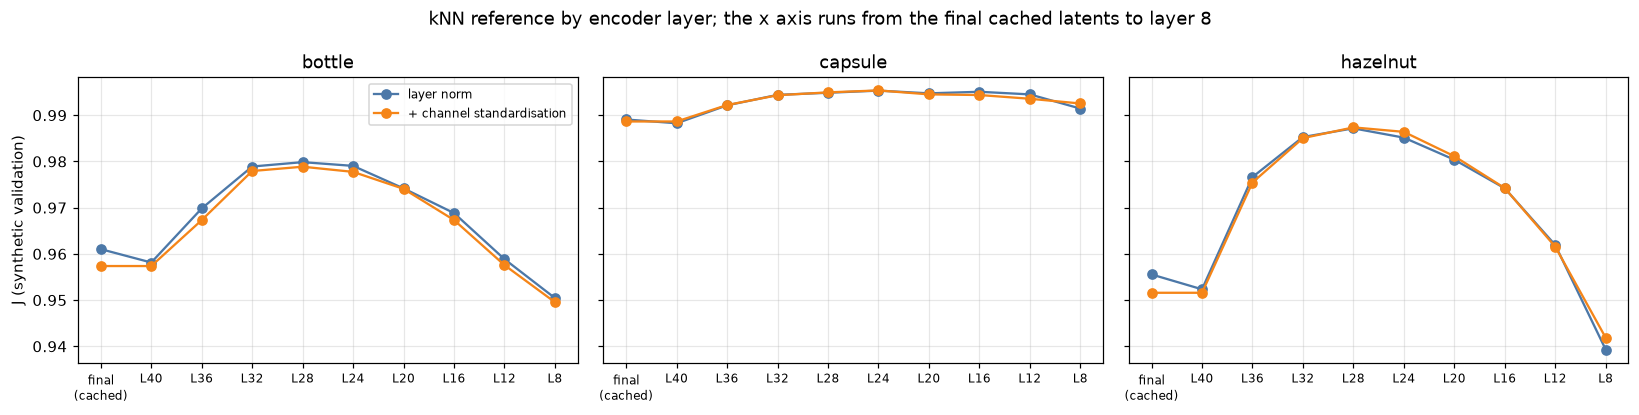

In [6]:
# selection: best J_mean, earliest option in the declared order within TIE_MARGIN (options x treatments order)
ordered = mean_df.reset_index(drop=True)
best = ordered.J.max()
winner = ordered[ordered.J >= best - TIE_MARGIN].iloc[0]
print(f'best J = {best:.4f}; selected (earliest within {TIE_MARGIN}): {winner.option} / {winner.treatment}  (J = {winner.J:.4f})')
per_category = {c: scan_df[scan_df.category == c].sort_values('J', ascending=False).iloc[0][['option', 'treatment', 'J']].to_dict() for c in CATEGORIES}
display(pd.DataFrame(per_category).T)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
x = np.arange(len(OPTIONS))
for ax, category in zip(axes, CATEGORIES):
    for treatment, color in zip(TREATMENTS, ('#4C78A8', '#F58518')):
        view = scan_df[(scan_df.category == category) & (scan_df.treatment == treatment)].set_index('option').loc[OPTIONS]
        ax.plot(x, view.J, 'o-', color=color, label=treatment)
    ax.set_xticks(x)
    ax.set_xticklabels([o.replace('final (cached)', 'final\n(cached)').replace('layer ', 'L') for o in OPTIONS], fontsize=8)
    ax.set_title(category)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('J (synthetic validation)')
axes[0].legend(fontsize=8)
fig.suptitle('kNN reference by encoder layer; the x axis runs from the final cached latents to layer 8')
fig.tight_layout()
plt.show()

## 5. Save the selection

The test split has not been read. The selected layer (if it is not the final cached latents) still has to be encoded for the test split (`scripts/build_layer_features.py --splits test`) before it can be confirmed there, once.

In [7]:
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / 'figures').mkdir(exist_ok=True)
if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()] + list((OUTPUT_ROOT / 'figures').glob('*.png'))
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)))
scan_df.to_csv(OUTPUT_ROOT / 'layer_scan.csv', index=False)
fig.savefig(OUTPUT_ROOT / 'figures' / 'layer_scan.png', dpi=150, bbox_inches='tight')
(OUTPUT_ROOT / 'selected_layer.json').write_text(json.dumps({
    'selected': {'option': winner.option, 'treatment': winner.treatment, 'J_mean': float(winner.J)},
    'best_J_mean': float(best), 'tie_margin': TIE_MARGIN,
    'declared_before_results': {
        'layers': list(LAYERS), 'treatments': list(TREATMENTS), 'order': OPTIONS, 'k': K,
        'criterion': 'mean over categories of mean(image AUROC top-k, pixel AUROC, AUPRO) on the synthetic validation set',
        'score': 'L2 distance to the nearest nominal training token (memory bank of all training tokens of the category)',
    },
    'per_category_best': per_category,
    'chosen_from': 'synthetic-anomaly validation set (nominal validation images + fixed-seed synthetic defects)',
    'test_split_read': False, 'test_used_for_selection': False,
    'feature_provenance': {'target_encoder_sha256': ENCODER_SHA256, 'normalisation': 'parameter-free token layer norm'},
}, indent=2, sort_keys=True, default=str), encoding='utf-8')
print('saved', OUTPUT_ROOT)

saved C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\layer_scan


## What you can and cannot say

**You can say**

* Which layer of the frozen target encoder has the most nearest-neighbour signal on the synthetic validation set, chosen without the test split, and how the final-layer reference compares.
* Whether the best layer is the same for all three categories (the per-category table).

**You cannot say**

* That the chosen layer is best on the real test split. That needs one test evaluation of the chosen layer, which this notebook does not do.
* That a predictor trained on the chosen layer will recover the kNN signal. The scan measures signal in the features, not what a 4-layer predictor can extract.
* Anything about a memory-free method from the kNN numbers: they are an analysis tool that uses a memory bank of every nominal training token.
* That synthetic defects represent MVTec defects. Notebook 06 found the synthetic ranking mostly agrees with the test ranking, but weakly for capsule's max score.